In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # raiz do repo, para encontrar o src

import torch
from src.retrievers.models.bert_loading import load_bert_encoder

In [2]:
encoder, tokenizer = load_bert_encoder("bert-base-uncased")
encoder.eval()

c:\Users\gonca\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 197/197 [00:00<00:00, 519.89it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
bert.pooler.dense.weight           

TransformerEncoder(
  (model): TransformerEncoder(
    (embeddings): Embeddings(
      (tok): Embedding(30522, 768)
      (pos): LearnedPositionalEmbedding(
        (pe): Embedding(512, 768)
      )
      (norm): LayerNorm()
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x EncoderLayer(
        (self_attn): MultiHeadedAttention(
          (linears): ModuleList(
            (0-3): 4 x Linear(in_features=768, out_features=768, bias=True)
          )
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (feed_forward): PositionwiseFeedForward(
          (w_1): Linear(in_features=768, out_features=3072, bias=True)
          (w_2): Linear(in_features=3072, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (activation): GELU(approximate='none')
        )
        (sublayer): ModuleList(
          (0-1): 2 x SublayerConnection(
            (norm): LayerNorm()
            (dropout): Dropout(p

In [3]:
text = "The bank of the river was flooded."
batch = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    encoder(batch["input_ids"], batch["attention_mask"])

maps = encoder.attention_maps()
tokens = tokenizer.convert_ids_to_tokens(batch["input_ids"][0])

print(tokens)
print(len(maps), maps[0].shape)

['[CLS]', 'the', 'bank', 'of', 'the', 'river', 'was', 'flooded', '.', '[SEP]']
12 torch.Size([1, 12, 10, 10])


In [4]:
import matplotlib.pyplot as plt

def plot_head(maps, tokens, layer, head, ax=None):
    att = maps[layer][0, head]              # (T, T), batch 0
    if ax is None:
        ax = plt.gca()
    ax.imshow(att, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(tokens)))
    ax.set_yticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=90)
    ax.set_yticklabels(tokens)
    ax.set_title(f"Layer {layer + 1}, head {head + 1}")

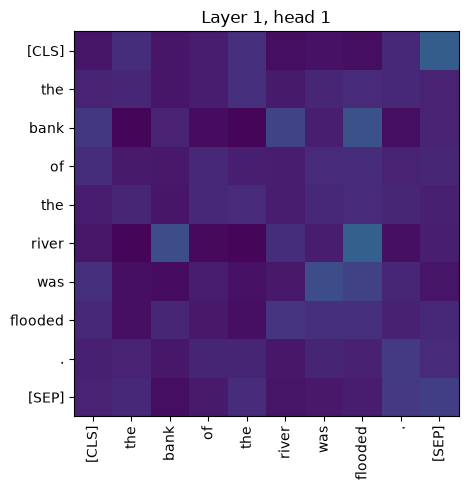

In [5]:
plt.figure(figsize=(5, 5))
plot_head(maps, tokens, layer=0, head=0)
plt.show()

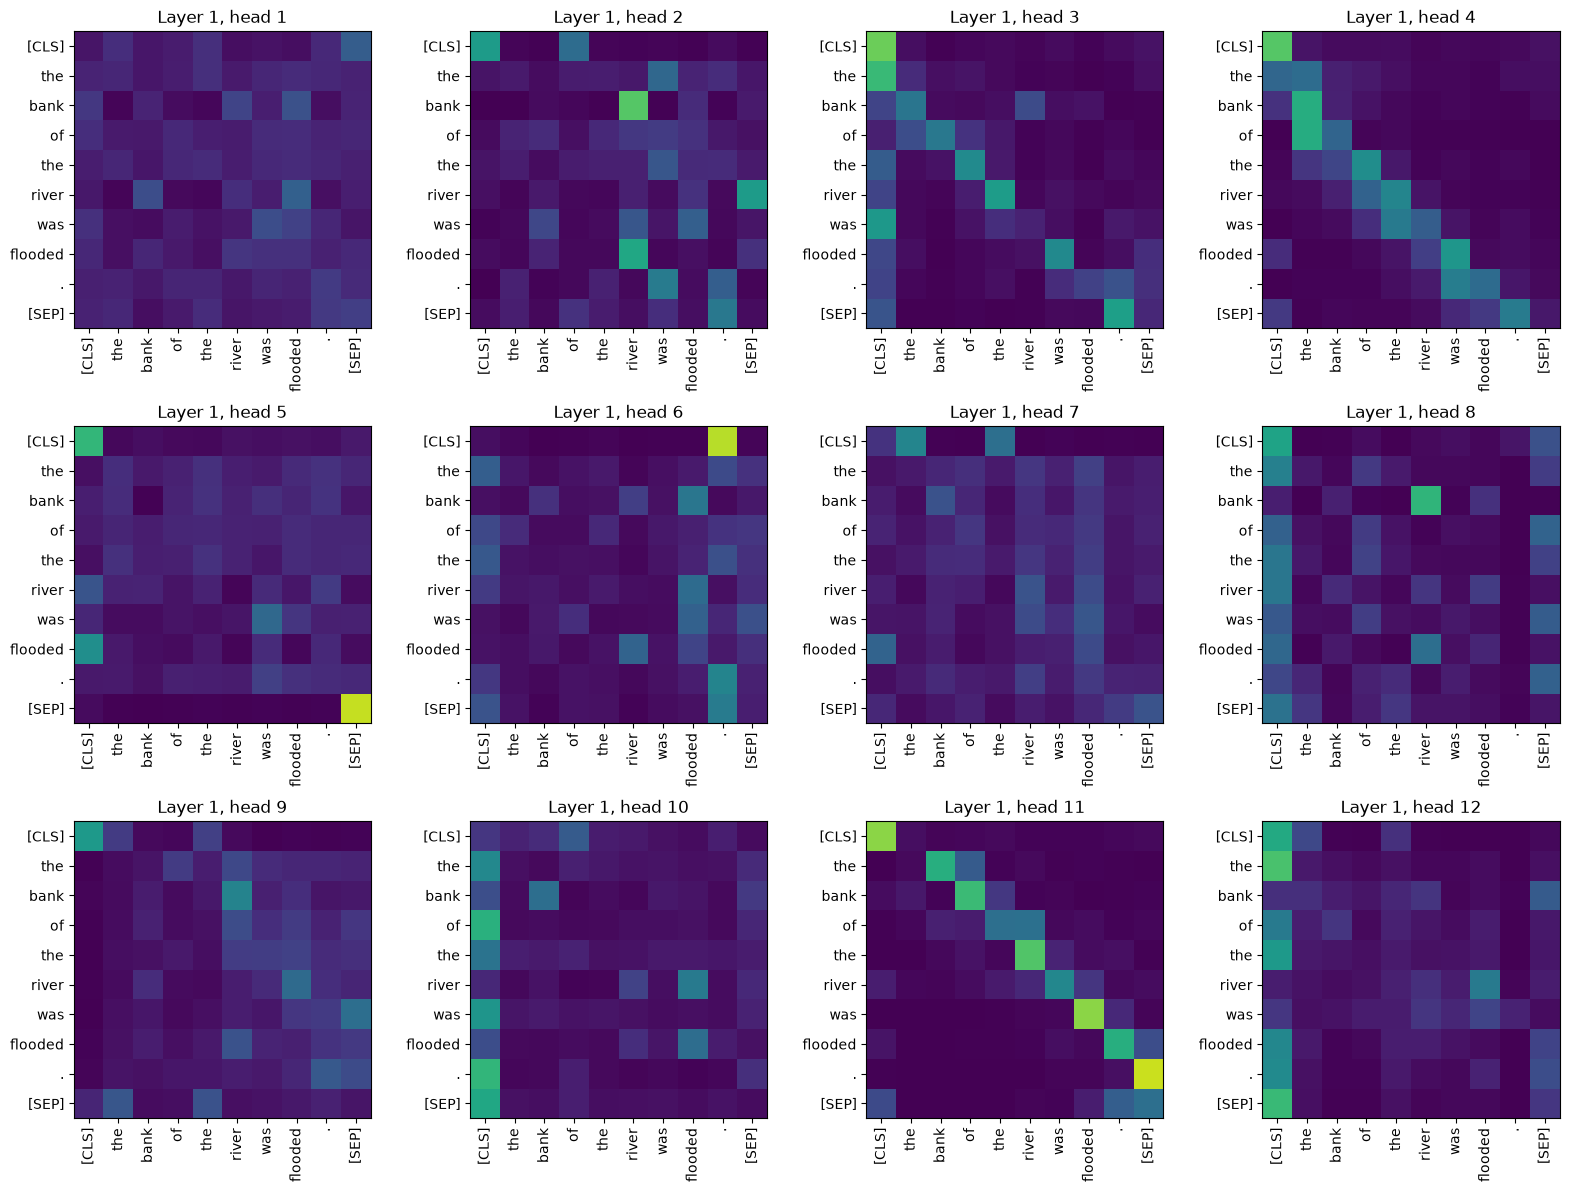

In [6]:
def plot_layer(maps, tokens, layer):
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    for head, ax in enumerate(axes.flat):
        plot_head(maps, tokens, layer, head, ax)
    plt.tight_layout()
    plt.show()

plot_layer(maps, tokens, layer=0)

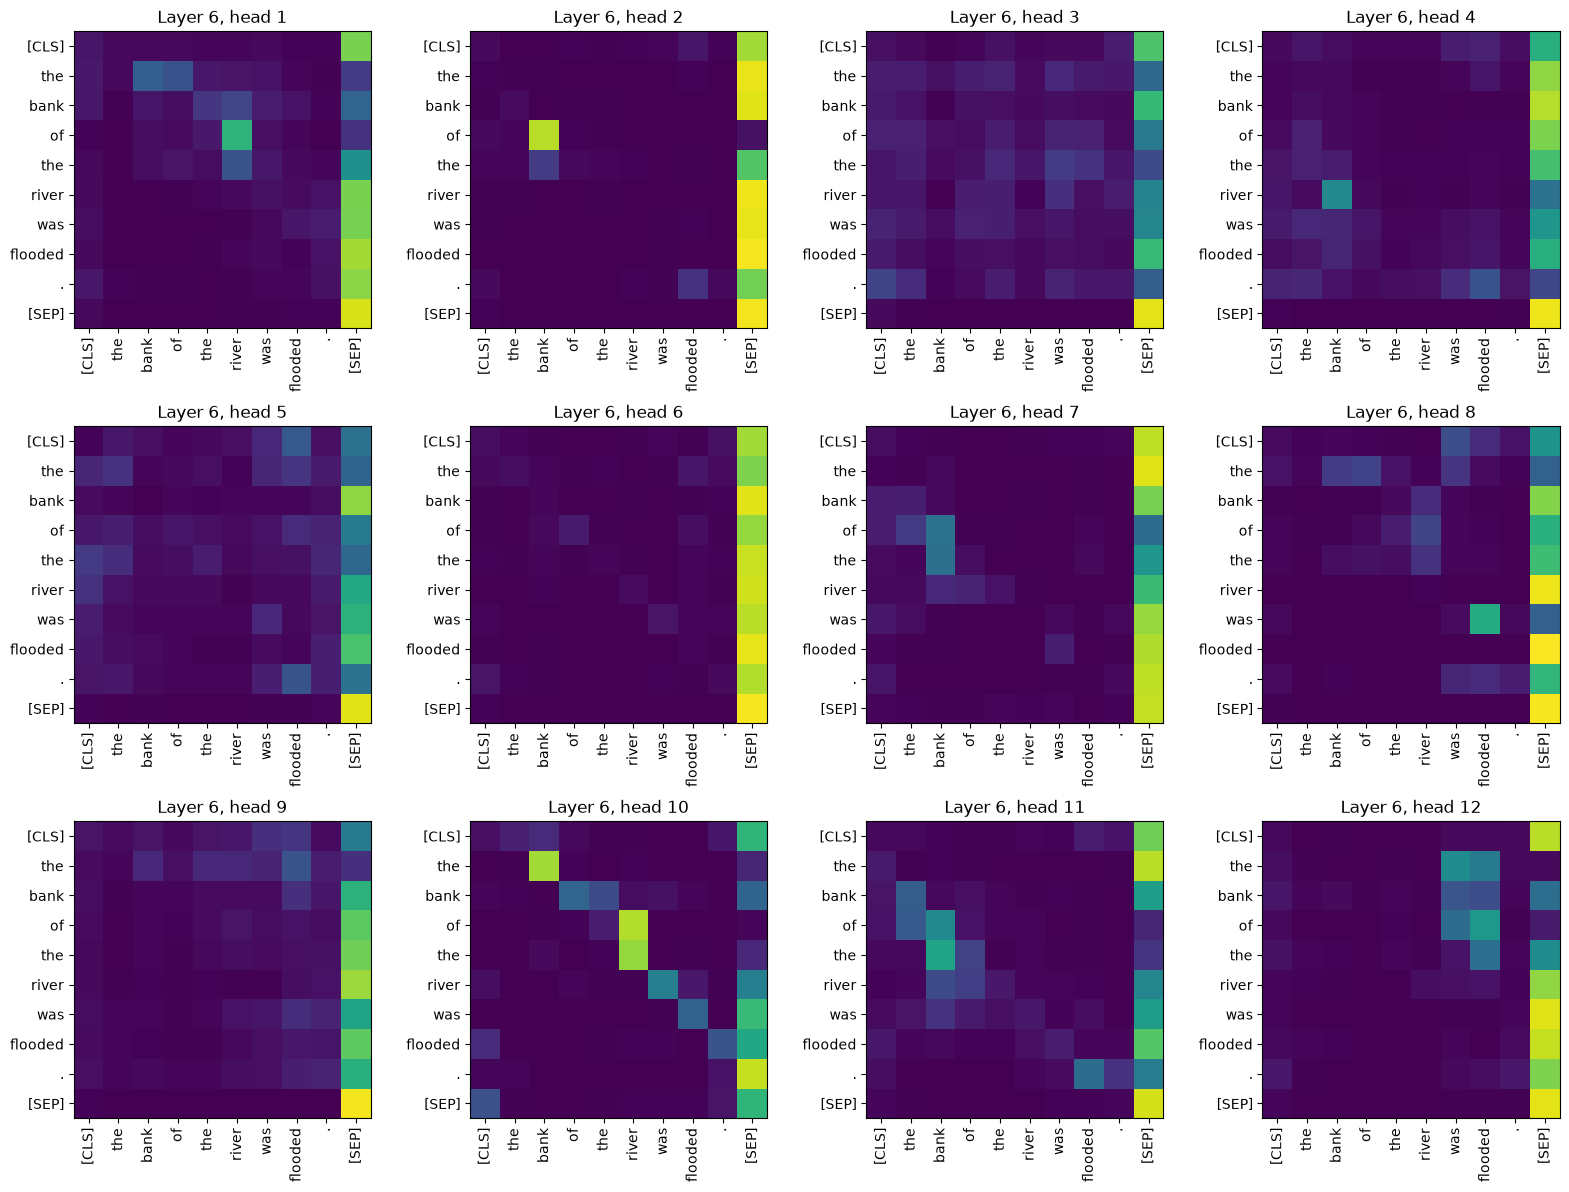

In [8]:
plot_layer(maps, tokens, layer=5)

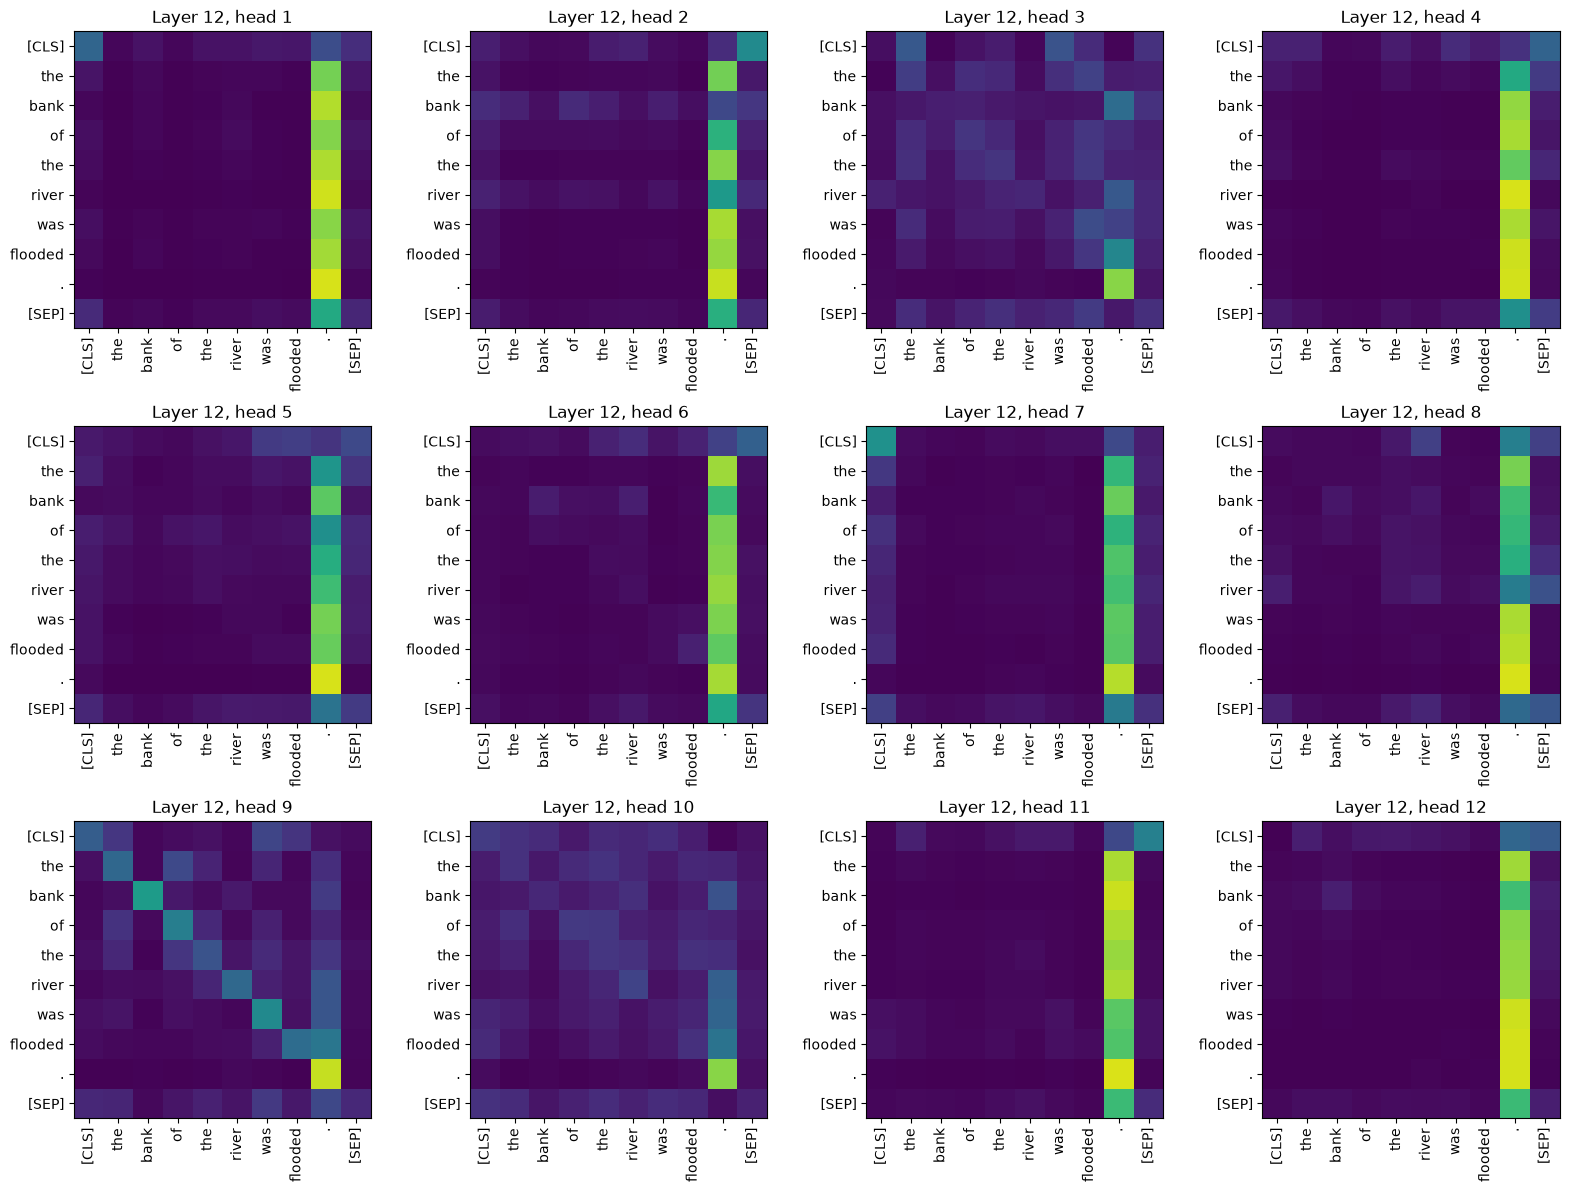

In [9]:
plot_layer(maps, tokens, layer=11)

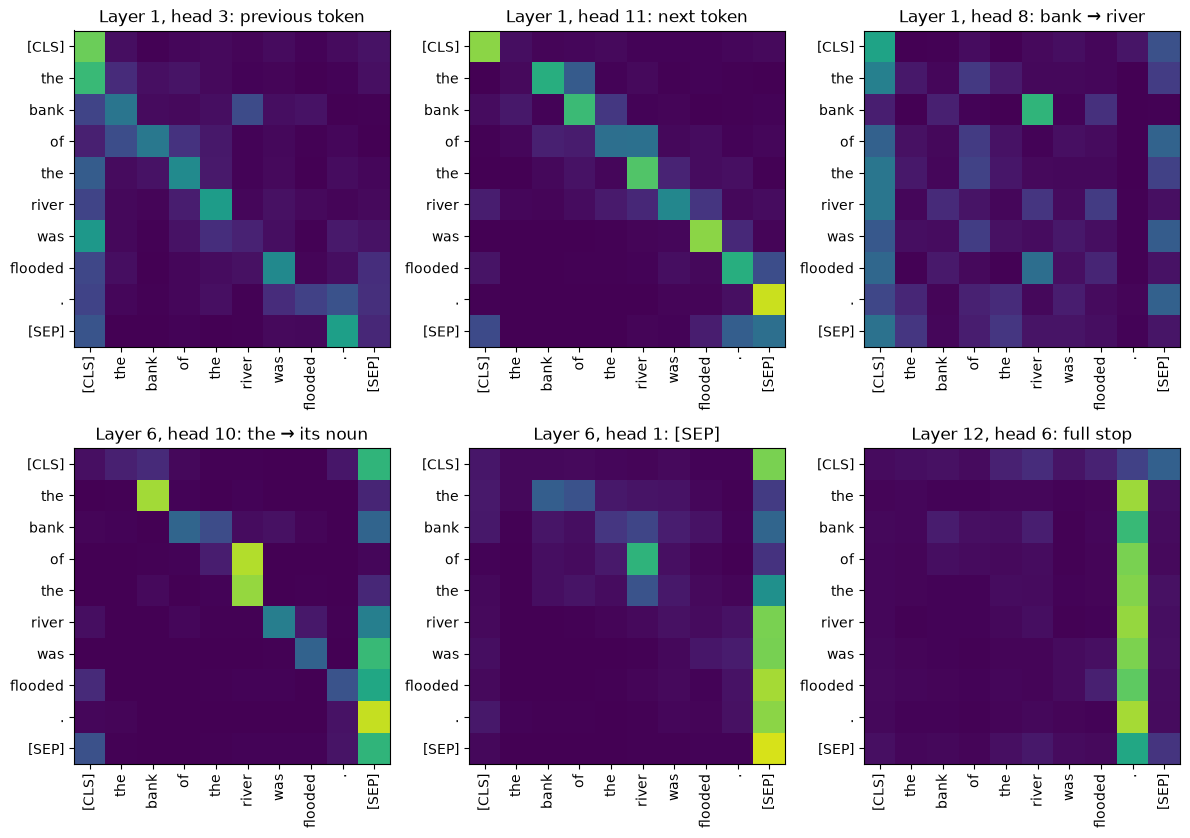

In [10]:
chosen = [
    (0, 2,  "previous token"),
    (0, 10, "next token"),
    (0, 7,  "bank → river"),
    (5, 9,  "the → its noun"),
    (5, 0,  "[SEP]"),
    (11, 5, "full stop"),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8.5))
for (layer, head, label), ax in zip(chosen, axes.flat):
    plot_head(maps, tokens, layer, head, ax)
    ax.set_title(f"Layer {layer + 1}, head {head + 1}: {label}")
plt.tight_layout()
plt.savefig("attention_maps.pdf", bbox_inches="tight")
plt.show()